# Tool selection with Unsloth (xLAM 60k)
Prepare the data first: `python prepare_xlam_data.py` (see README).

In [2]:
from unsloth import FastDecisionModel, DecisionTrainer, is_bfloat16_supported
from datasets import load_dataset
from transformers import TrainingArguments
import json, collections

TRAIN_N, TEST_N = 5000, 500      # subset sizes for a quick first run; use None for the full set (13,821 / 1,000)

model, tokenizer = FastDecisionModel.from_pretrained(
    model_name = "unsloth/Qwen3.5-2B",
    max_seq_length = 512,        # prompts are short (median ~130 tokens, max ~320)
    load_in_4bit = True,
)

c:\Users\Rajeev.Ranjan\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\unsloth\__init__.py:1633: UserWarning: WARNING: Unsloth should be imported before [transformers] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1015 18:41:26.049000 59424 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.5: Fast Qwen3_5 patching. Transformers: 5.12.1.
   \\   /|    NVIDIA GeForce RTX 5050 Laptop GPU. Num GPUs = 1. Max memory: 7.96 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 12.0. CUDA Toolkit: 12.8. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d
Fetching 13 files: 100%|██████████| 13/13 [00:00<00:00, 866.74it/s]


## 1. Load data and build decision items

In [3]:
raw = load_dataset("json", data_files={"train":"data/xlam_train.jsonl","test":"data/xlam_test.jsonl"})
train_raw = raw["train"].shuffle(seed=3407); test_raw = raw["test"].shuffle(seed=3407)
if TRAIN_N: train_raw = train_raw.select(range(TRAIN_N))
if TEST_N:  test_raw  = test_raw.select(range(TEST_N))
train_items, r1 = FastDecisionModel.build_dataset(train_raw, tokenizer, model)
test_items,  r2 = FastDecisionModel.build_dataset(test_raw,  tokenizer, model)
print("train skipped", r1["skipped"], "of", r1["total"], "| test skipped", r2["skipped"], "of", r2["total"])

Generating train split: 13821 examples [00:00, 166530.14 examples/s]
Generating test split: 1000 examples [00:00, 54427.66 examples/s]


Unsloth: 1 of 5,000 training inputs are longer than max_seq_length = 512, so the end of their state is cut. Raise max_seq_length to train on all of it.
train skipped 0 of 5000 | test skipped 0 of 500


## 2. BEFORE training

In [4]:
before = FastDecisionModel.evaluate(model, tokenizer, test_items)
print("BEFORE:", before)

BEFORE: {'accuracy': 0.506, 'ece': 0.2195425419807434, 'loss': 1.2804080231189727, 'record_accuracy': 0.506}


## 3. Train

In [5]:
model = FastDecisionModel.get_peft_model(
    model, r = 16, lora_alpha = 16, lora_dropout = 0,
    use_gradient_checkpointing = "unsloth", random_state = 3407,
)
trainer = DecisionTrainer(
    model = model, processing_class = tokenizer,
    train_dataset = train_items, eval_dataset = test_items,
    args = TrainingArguments(
        per_device_train_batch_size = 8, gradient_accumulation_steps = 4,
        num_train_epochs = 2, learning_rate = 2e-4, lr_scheduler_type = "cosine",
        warmup_steps = 10, weight_decay = 0.01,
        bf16 = is_bfloat16_supported(), fp16 = not is_bfloat16_supported(),
        eval_strategy = "epoch", logging_steps = 10,
        output_dir = "outputs", report_to = "none", seed = 3407,
    ),
)
trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 5,000 | Num Epochs = 2 | Total steps = 314
O^O/ \_/ \    Batch size per device = 8 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (8 x 4 x 1) = 32
 "-____-"     Trainable parameters = 47,291,908 of 1,688,011,076 (2.80% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Epoch,Training Loss,Validation Loss
1,0.008655,0.002643
2,0.010303,0.001876


Unsloth: Restored added_tokens_decoder metadata in outputs\checkpoint-314\.unsloth-save-96ryy87q\tokenizer_config.json.


TrainOutput(global_step=314, training_loss=0.04973781137107308, metrics={'train_runtime': 57350.8791, 'train_samples_per_second': 0.174, 'train_steps_per_second': 0.005, 'total_flos': 0.0, 'train_loss': 0.04973781137107308, 'epoch': 2.0})

## 4. AFTER training: accuracy + calibration

In [6]:
after = FastDecisionModel.evaluate(model, tokenizer, test_items)
print("AFTER:", after)
print(FastDecisionModel.calibrate(model, tokenizer, test_items))   # accuracy, ece, loss

AFTER: {'accuracy': 1.0, 'ece': 0.0016412236690521134, 'loss': 0.0018333696737503544, 'record_accuracy': 1.0}
{'accuracy': 1.0, 'ece': 2.559423446624187e-06, 'loss': 2.5611207820475102e-06, 'record_accuracy': 1.0, 'fitted_types': [0]}


## 5. Accuracy by number of candidate tools, and wrong predictions

In [7]:
FastDecisionModel.for_inference(model)
hit, tot, wrong = collections.Counter(), collections.Counter(), []
for r in test_raw:
    q = json.loads(r["questions"]); text = json.loads(r["state"])["message"]
    gold = json.loads(r["gold"])["tool"]["label"]; n = len(q["tool"]["criteria"])
    pred = FastDecisionModel.predict(model, tokenizer, text, q)["tool"]["answer"]
    tot[n] += 1; hit[n] += pred == gold
    if pred != gold: wrong.append((text, gold, pred))
for n in sorted(tot): print(f"{n} options: {hit[n]}/{tot[n]} = {hit[n]/tot[n]:.1%}")
print(f"OVERALL {sum(hit.values())}/{sum(tot.values())} = {sum(hit.values())/sum(tot.values()):.1%}")
for w in wrong[:15]: print(w)

3 options: 196/196 = 100.0%
4 options: 258/258 = 100.0%
5 options: 46/46 = 100.0%
OVERALL 500/500 = 100.0%


## 6. Before vs after

In [8]:
print("BEFORE:", before)
print("AFTER :", after)

BEFORE: {'accuracy': 0.506, 'ece': 0.2195425419807434, 'loss': 1.2804080231189727, 'record_accuracy': 0.506}
AFTER : {'accuracy': 1.0, 'ece': 0.0016412236690521134, 'loss': 0.0018333696737503544, 'record_accuracy': 1.0}


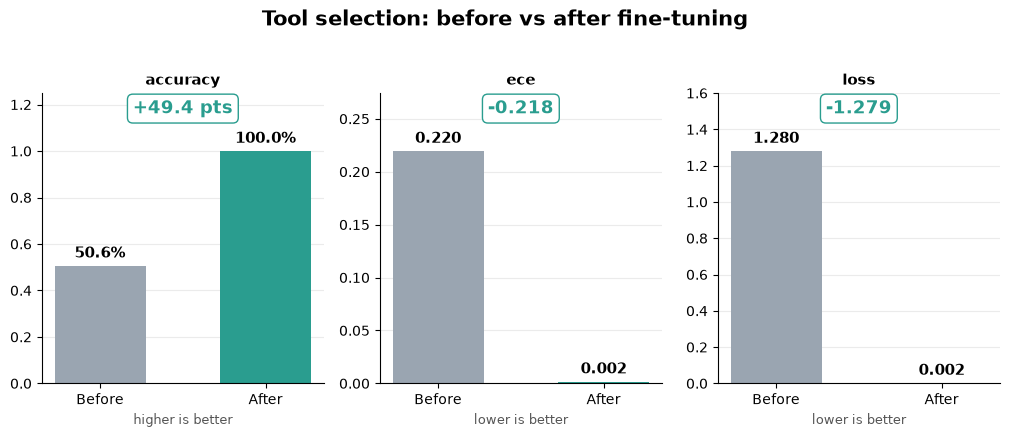

metric                    before     after    change
accuracy                  0.5060    1.0000   +0.4940
ece                       0.2195    0.0016   -0.2179
loss                      1.2804    0.0018   -1.2786


In [11]:
import matplotlib.pyplot as plt
import numbers

def flat(d, p=""):
    out = {}
    for k, v in d.items():
        if isinstance(v, dict): out.update(flat(v, f"{p}{k}."))
        elif isinstance(v, numbers.Number) and not isinstance(v, bool): out[f"{p}{k}"] = float(v)
    return out

b, a = flat(before), flat(after)
LOWER = ("loss", "ece", "error", "brier", "nll")          # lower is better; everything else: higher is better
metrics = []
for k in b:                                               # skip metrics that duplicate an earlier one (e.g. record_accuracy)
    if k in a and not any((b[k], a[k]) == (b[m], a[m]) for m in metrics): metrics.append(k)
BEFORE_C, AFTER_C, GOOD, BAD = "#9aa5b1", "#2a9d8f", "#2a9d8f", "#e76f51"

fig, axes = plt.subplots(1, len(metrics), figsize=(3.4 * len(metrics), 4.2), squeeze=False)
fig.suptitle("Tool selection: before vs after fine-tuning", fontsize=15, fontweight="bold", y=1.03)
for ax, k in zip(axes[0], metrics):
    lower = any(w in k.lower() for w in LOWER)
    bars = ax.bar(["Before", "After"], [b[k], a[k]], color=[BEFORE_C, AFTER_C], width=0.55)
    top = max(b[k], a[k]) or 1
    for bar, v in zip(bars, (b[k], a[k])):
        ax.text(bar.get_x() + bar.get_width() / 2, v + top * 0.02, f"{v:.1%}" if v <= 1 and not lower else f"{v:.3f}",
                ha="center", va="bottom", fontsize=11, fontweight="bold")
    d = a[k] - b[k]; better = d < 0 if lower else d > 0
    ax.set_title(k, fontsize=11, fontweight="bold"); ax.set_xlabel("lower is better" if lower else "higher is better", fontsize=9, color="#555")
    ax.text(0.5, 0.93, f"{d:+.3f}" if lower or abs(d) > 1 else f"{d * 100:+.1f} pts", transform=ax.transAxes, ha="center",
            fontsize=13, fontweight="bold", color=GOOD if better else BAD,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GOOD if better else BAD))
    ax.set_ylim(0, top * 1.25)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

print(f"{'metric':<22}{'before':>10}{'after':>10}{'change':>10}")
for k in metrics: print(f"{k:<22}{b[k]:>10.4f}{a[k]:>10.4f}{a[k]-b[k]:>+10.4f}")


## 7. Save and try it on your own tools

In [9]:
model.save_pretrained("xlam-tool-selector")
tools = {"get_weather": "Get the current weather for a city | params: city",
         "send_email": "Send an email to a recipient | params: to, subject, body",
         "search_flights": "Search flights between two airports on a date | params: origin, destination, date",
         "convert_currency": "Convert an amount from one currency to another | params: amount, from, to"}
q = {"tool": {"type": "choice", "instructions": "Which tool should be called to answer this request?", "criteria": tools}}
for text in ["is it raining in Berlin right now?", "how much is 250 euros in rupees", "write to bob that the meeting moved"]:
    a = FastDecisionModel.predict(model, tokenizer, text, q)["tool"]
    print(text, "->", a["answer"], a["probabilities"])

Unsloth: Restored added_tokens_decoder metadata in xlam-tool-selector\.unsloth-save-qi1e08dj\tokenizer_config.json.


is it raining in Berlin right now? -> get_weather {'get_weather': 1.0, 'send_email': 0.0, 'search_flights': 0.0, 'convert_currency': 0.0}
how much is 250 euros in rupees -> convert_currency {'get_weather': 0.0, 'send_email': 0.0, 'search_flights': 0.0, 'convert_currency': 1.0}
write to bob that the meeting moved -> send_email {'get_weather': 0.0, 'send_email': 1.0, 'search_flights': 0.0, 'convert_currency': 0.0}
